<a href="https://colab.research.google.com/github/keyvanmahmoudi/Data_Science_Course/blob/main/sessions/Session01_numpy_fundamentals.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

# جلسهٔ ۱: NumPy، پایهٔ محاسبات عددی در پایتون

تقریباً همهٔ کتابخانه‌های علم داده (Pandas، Matplotlib، scikit-learn، PyTorch) روی آرایه‌های NumPy ساخته شده‌اند. کسی که NumPy را خوب بشناسد، بقیهٔ ابزارها را سریع‌تر یاد می‌گیرد.

### اهداف این جلسه

- آشنایی با چرخهٔ کار در علم داده و جایگاه NumPy در آن
- ساختن آرایه و شناخت `shape`، `ndim` و `dtype`
- اندیس‌گذاری، برش (slicing)، اندیس‌گذاری بولی و اندیس‌گذاری با لیست
- **برداری‌سازی (Vectorization)**: چرا حلقهٔ `for` روی دادهٔ عددی کند است
- **پخش (Broadcasting)**: انجام عملیات روی آرایه‌هایی با شکل متفاوت
- تجمیع (sum، mean، ...) روی محورهای مختلف
- تغییر شکل آرایه و تولید عدد تصادفی با `default_rng`

</div>

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

## ۱. چرخهٔ کار در علم داده

یک پروژهٔ داده معمولاً این مراحل را طی می‌کند:

1. **طرح سؤال**: دقیقاً می‌خواهیم چه چیزی را بفهمیم یا پیش‌بینی کنیم؟
2. **جمع‌آوری داده**: از فایل، پایگاه داده (SQL)، API و ...
3. **پاک‌سازی و آماده‌سازی**: رفع مقادیر گمشده، خطاها و ناسازگاری‌ها
4. **تحلیل اکتشافی (EDA)**: شناخت داده با آمار توصیفی و نمودار
5. **مدل‌سازی و آزمون آماری**: پاسخ کمّی به سؤال
6. **ارائهٔ نتیجه**: گزارش، نمودار و داشبورد برای تصمیم‌گیرنده

در این ترم ابزار همهٔ این مراحل، به‌جز مدل‌سازی یادگیری ماشین (ترم بعد)، را یاد می‌گیریم.

</div>

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

## ۲. چرا NumPy؟

لیست پایتون می‌تواند هر نوع شیئی را نگه دارد؛ همین انعطاف آن را کند می‌کند. آرایهٔ NumPy فقط یک نوع داده دارد و عناصرش پشت سر هم در حافظه ذخیره می‌شوند، پس عملیات روی آن با کد کامپایل‌شدهٔ C انجام می‌شود.

بیایید جمع مربع یک میلیون عدد را با دو روش مقایسه کنیم:

</div>

In [1]:
import timeit
import numpy as np

n = 1_000_000
py_list = list(range(n))
np_array = np.arange(n)

t_py = min(timeit.repeat(lambda: sum(x * x for x in py_list), number=1, repeat=5))
t_np = min(timeit.repeat(lambda: (np_array ** 2).sum(), number=1, repeat=5))
total_py = sum(x * x for x in py_list)
total_np = int((np_array ** 2).sum())

print(f"Python loop : {t_py * 1000:7.1f} ms")
print(f"NumPy       : {t_np * 1000:7.1f} ms")
print(f"Speed-up    : {t_py / t_np:7.1f}x")
print("Same result:", total_py == total_np)

Python loop :    28.6 ms
NumPy       :     0.8 ms
Speed-up    :    34.4x
Same result: True


<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

روی همین سیستم NumPy چندده برابر سریع‌تر است (عدد دقیق به سخت‌افزار بستگی دارد). به این سبک نوشتن، یعنی اعمال یک عملیات روی کل آرایه به‌جای حلقه روی تک‌تک عناصر، **برداری‌سازی** می‌گویند.

> قرارداد رایج: NumPy همیشه با نام کوتاه `np` وارد می‌شود.

</div>

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

## ۳. ساختن آرایه

راه‌های اصلی ساختن آرایه:

</div>

In [2]:
a = np.array([3, 1, 4, 1, 5, 9])          # from a list
b = np.array([[1, 2, 3], [4, 5, 6]])      # 2-D from nested lists

print(a)
print(b)
print("zeros :", np.zeros(4))
print("ones  :", np.ones((2, 3)))
print("arange:", np.arange(0, 10, 2))      # like range(): start, stop (excluded), step
print("linspace:", np.linspace(0, 1, 5))   # 5 evenly spaced numbers, stop included
print("full  :", np.full(3, 7))
print("eye   :\n", np.eye(3))              # identity matrix

[3 1 4 1 5 9]
[[1 2 3]
 [4 5 6]]
zeros : [0. 0. 0. 0.]
ones  : [[1. 1. 1.]
 [1. 1. 1.]]
arange: [0 2 4 6 8]
linspace: [0.   0.25 0.5  0.75 1.  ]
full  : [7 7 7]
eye   :
 [[1. 0. 0.]
 [0. 1. 0.]
 [0. 0. 1.]]


<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

### ویژگی‌های یک آرایه

- `ndim`: تعداد ابعاد (محورها)
- `shape`: اندازه در هر بعد
- `size`: تعداد کل عناصر
- `dtype`: نوع دادهٔ عناصر

</div>

In [3]:
for name, arr in [("a", a), ("b", b)]:
    print(f"{name}: ndim={arr.ndim}, shape={arr.shape}, size={arr.size}, dtype={arr.dtype}")

a: ndim=1, shape=(6,), size=6, dtype=int64
b: ndim=2, shape=(2, 3), size=6, dtype=int64


<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

### نوع داده (dtype)

همهٔ عناصر یک آرایه هم‌نوع‌اند. اگر نوع‌ها را مخلوط کنیم، NumPy همه را به «عمومی‌ترین» نوع تبدیل می‌کند. انتخاب dtype روی حافظه و دقت اثر دارد:

</div>

In [4]:
print(np.array([1, 2, 3]).dtype)          # int64
print(np.array([1, 2.5, 3]).dtype)        # float64: ints are upcast
print(np.array([1, "2", 3]).dtype)        # <U21: everything became a string!

x = np.arange(1_000_000, dtype=np.float64)
y = x.astype(np.float32)
print(f"float64: {x.nbytes / 1e6:.0f} MB   float32: {y.nbytes / 1e6:.0f} MB")

int64
float64
<U21
float64: 8 MB   float32: 4 MB


<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

> **نکته:** وقتی فایل داده را می‌خوانیم و یک ستون عددی ناگهان از نوع رشته (`object` یا `<U`) می‌شود، معمولاً یعنی یک مقدار غیرعددی (مثل «ندارد» یا `1,250`) در آن ستون هست. در جلسهٔ ۳ با این مشکل روبه‌رو می‌شویم.

</div>

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

## ۴. اندیس‌گذاری و برش

اندیس‌ها از صفر شروع می‌شوند و اندیس منفی از انتها می‌شمارد. برای آرایهٔ دوبعدی، اندیس را به شکل `[سطر, ستون]` می‌نویسیم.

</div>

In [5]:
a = np.array([10, 20, 30, 40, 50, 60])
print(a[0], a[-1])        # first and last
print(a[1:4])             # elements 1, 2, 3
print(a[::2])             # every second element
print(a[::-1])            # reversed

m = np.arange(1, 13).reshape(3, 4)
print(m)
print("m[1, 2]  =", m[1, 2])
print("row 0    =", m[0])
print("column 1 =", m[:, 1])
print("sub-matrix:\n", m[:2, 1:3])

10 60
[20 30 40]
[10 30 50]
[60 50 40 30 20 10]
[[ 1  2  3  4]
 [ 5  6  7  8]
 [ 9 10 11 12]]
m[1, 2]  = 7
row 0    = [1 2 3 4]
column 1 = [ 2  6 10]
sub-matrix:
 [[2 3]
 [6 7]]


<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

### برش، «نما» (view) است نه کپی

برش یک آرایه، داده را کپی نمی‌کند؛ فقط یک «نما» روی همان حافظه می‌سازد. پس تغییر برش، آرایهٔ اصلی را هم تغییر می‌دهد. برای داشتن نسخهٔ مستقل از `copy()` استفاده کنید.

</div>

In [6]:
m = np.arange(1, 13).reshape(3, 4)
first_row = m[0]
first_row[:] = 0
print(m)              # the original changed too

m = np.arange(1, 13).reshape(3, 4)
safe = m[0].copy()
safe[:] = 0
print(m[0])           # unchanged

[[ 0  0  0  0]
 [ 5  6  7  8]
 [ 9 10 11 12]]
[1 2 3 4]


<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

### اندیس‌گذاری بولی: فیلتر کردن داده

مقایسه روی آرایه، یک آرایهٔ بولی (True/False) می‌دهد. با همین آرایه می‌توانیم عناصر دلخواه را جدا کنیم. این مهم‌ترین ابزار فیلتر کردن داده است و در Pandas هم دقیقاً به همین شکل کار می‌کند.

ترکیب شرط‌ها با `&` (و)، `|` (یا) و `~` (نقیض) انجام می‌شود و هر شرط باید داخل پرانتز باشد.

</div>

In [7]:
temps = np.array([12.5, 18.0, 25.3, 31.2, 8.4, 22.1, 35.6])
mask = temps > 20
print(mask)
print("hot days     :", temps[mask])
print("mild (15-30) :", temps[(temps >= 15) & (temps <= 30)])
print("extreme      :", temps[(temps < 10) | (temps > 33)])
print("count > 20   :", mask.sum())         # True counts as 1
print("share > 20   :", mask.mean().round(2))

[False False  True  True False  True  True]
hot days     : [25.3 31.2 22.1 35.6]
mild (15-30) : [18.  25.3 22.1]
extreme      : [ 8.4 35.6]
count > 20   : 4
share > 20   : 0.57


<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

### اندیس‌گذاری با لیست (Fancy indexing) و `np.where`

- با یک لیست از اندیس‌ها می‌توان چند عنصر دلخواه را با هر ترتیبی انتخاب کرد.
- `np.where(شرط, مقدار_اگر_درست, مقدار_اگر_غلط)` یک «if» برداری است.

</div>

In [8]:
print(temps[[0, 3, 6]])
labels = np.where(temps > 20, "hot", "cold")
print(labels)
clipped = np.clip(temps, 10, 30)        # force values into [10, 30]
print(clipped)

[12.5 31.2 35.6]
['cold' 'cold' 'hot' 'hot' 'cold' 'hot' 'hot']
[12.5 18.  25.3 30.  10.  22.1 30. ]


<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

## ۵. عملیات برداری و توابع جهانی (ufunc)

عملگرهای ریاضی روی آرایه‌ها **عنصربه‌عنصر** عمل می‌کنند. NumPy برای توابع ریاضی هم نسخهٔ برداری دارد (`np.sqrt`، `np.exp`، `np.log`، ...).

</div>

In [9]:
prices = np.array([120_000, 85_000, 300_000, 45_000])
qty = np.array([2, 5, 1, 10])

revenue = prices * qty
print("revenue:", revenue)
print("total  :", revenue.sum())
print("with 9% VAT:", (prices * 1.09).round())
print("sqrt:", np.sqrt(qty).round(3))
print("log :", np.log(prices).round(3))

revenue: [240000 425000 300000 450000]
total  : 1415000
with 9% VAT: [130800.  92650. 327000.  49050.]
sqrt: [1.414 2.236 1.    3.162]
log : [11.695 11.35  12.612 10.714]


<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

## ۶. پخش (Broadcasting)

وقتی دو آرایه شکل متفاوت دارند، NumPy در صورت امکان آرایهٔ کوچک‌تر را (بدون کپی واقعی) در طول بُعد گم‌شده «پخش» می‌کند. قاعده: شکل‌ها از **راست به چپ** مقایسه می‌شوند و دو بُعد سازگارند اگر برابر باشند یا یکی‌شان ۱ باشد.

| شکل A | شکل B | نتیجه |
|---|---|---|
| (3, 4) | () عدد | (3, 4) |
| (3, 4) | (4,) | (3, 4) |
| (3, 4) | (3, 1) | (3, 4) |
| (3, 4) | (3,) | خطا |

یک کاربرد بسیار رایج: **استانداردسازی** ستون‌های یک ماتریس داده (کم کردن میانگین و تقسیم بر انحراف معیار هر ستون).

</div>

In [10]:
rng = np.random.default_rng(42)
# 5 students x 3 exams, each exam on a different scale
scores = np.column_stack([
    rng.normal(15, 2, 5),     # out of 20
    rng.normal(70, 10, 5),    # out of 100
    rng.normal(4, 0.5, 5),    # out of 5
]).round(1)
print(scores)

col_mean = scores.mean(axis=0)      # shape (3,)
col_std = scores.std(axis=0)        # shape (3,)
z = (scores - col_mean) / col_std   # (5, 3) op (3,) -> broadcast over rows
print("\nstandardized:\n", z.round(2))
print("column means are now zero:", np.allclose(z.mean(axis=0), 0))
print("column stds are now one   :", np.allclose(z.std(axis=0), 1))

[[15.6 57.   4.4]
 [12.9 71.3  4.4]
 [16.5 66.8  4. ]
 [16.9 69.8  4.6]
 [11.1 61.5  4.2]]

standardized:
 [[ 0.45 -1.55  0.39]
 [-0.76  1.13  0.39]
 [ 0.85  0.29 -1.57]
 [ 1.03  0.85  1.37]
 [-1.56 -0.71 -0.59]]
column means are now zero: True
column stds are now one   : True


<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

برای پخش در جهت سطرها (مثلاً کم کردن میانگین هر **سطر**)، باید آرایهٔ میانگین را به شکل ستونی `(5, 1)` دربیاوریم. پارامتر `keepdims=True` همین کار را می‌کند:

</div>

In [11]:
row_mean = scores.mean(axis=1, keepdims=True)   # shape (5, 1)
print(row_mean.shape)
print((scores - row_mean).round(1))

(5, 1)
[[-10.1  31.3 -21.3]
 [-16.6  41.8 -25.1]
 [-12.6  37.7 -25.1]
 [-13.5  39.4 -25.8]
 [-14.5  35.9 -21.4]]


<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

## ۷. تجمیع روی محورها

در آرایهٔ دوبعدی، `axis=0` یعنی «در امتداد سطرها» (نتیجه برای هر ستون) و `axis=1` یعنی «در امتداد ستون‌ها» (نتیجه برای هر سطر). یک راه ساده برای به خاطر سپردن: محوری که مشخص می‌کنید، **حذف** می‌شود.

</div>

In [12]:
sales = np.array([
    [12, 15, 9, 20],    # branch 1, four quarters
    [30, 28, 35, 40],   # branch 2
    [7, 6, 8, 5],       # branch 3
])
print("total            :", sales.sum())
print("per quarter (ax0):", sales.sum(axis=0))
print("per branch  (ax1):", sales.sum(axis=1))
print("best quarter per branch:", sales.argmax(axis=1))
print("cumulative sales of branch 2:", sales[1].cumsum())

total            : 215
per quarter (ax0): [49 49 52 65]
per branch  (ax1): [ 56 133  26]
best quarter per branch: [3 3 2]
cumulative sales of branch 2: [ 30  58  93 133]


<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

## ۸. تغییر شکل و چسباندن آرایه‌ها

- `reshape`: تغییر شکل بدون تغییر داده (`-1` یعنی «خودت حساب کن»)
- `ravel` / `flatten`: تبدیل به یک‌بعدی
- `T`: ترانهاده
- `concatenate`، `vstack`، `hstack`: چسباندن آرایه‌ها

</div>

In [13]:
v = np.arange(12)
print(v.reshape(3, 4))
print(v.reshape(2, -1).shape)
print(v.reshape(3, 4).T.shape)

x = np.array([[1, 2], [3, 4]])
y = np.array([[5, 6]])
print(np.vstack([x, y]))
print(np.hstack([x, x]))

[[ 0  1  2  3]
 [ 4  5  6  7]
 [ 8  9 10 11]]
(2, 6)
(4, 3)
[[1 2]
 [3 4]
 [5 6]]
[[1 2 1 2]
 [3 4 3 4]]


<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

## ۹. اعداد تصادفی

برای شبیه‌سازی، نمونه‌گیری و ساختن دادهٔ آزمایشی به اعداد تصادفی نیاز داریم. روش توصیه‌شدهٔ امروزی، ساختن یک **مولد** با `np.random.default_rng(seed)` است. دادن `seed` باعث می‌شود نتایج **تکرارپذیر** باشند؛ یعنی هر کسی کد را اجرا کند، همان اعداد را می‌گیرد. این برای کار علمی ضروری است.

</div>

In [14]:
rng = np.random.default_rng(seed=2026)
print("integers :", rng.integers(1, 7, size=10))          # dice rolls
print("uniform  :", rng.random(3).round(3))
print("normal   :", rng.normal(loc=170, scale=8, size=4).round(1))
print("choice   :", rng.choice(["A", "B", "C"], size=6, p=[0.5, 0.3, 0.2]))
deck = np.arange(10)
rng.shuffle(deck)
print("shuffled :", deck)

integers : [6 2 1 4 3 3 1 3 4 3]
uniform  : [0.791 0.905 0.177]
normal   : [167.9 168.2 175.8 174.1]
choice   : ['B' 'B' 'B' 'C' 'A' 'A']
shuffled : [3 4 6 8 9 0 1 2 5 7]


<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

## ۱۰. مثال کاربردی: تصویر هم یک آرایه است

یک تصویر خاکستری، ماتریسی از اعداد بین ۰ (سیاه) تا ۲۵۵ (سفید) است. با همین ابزارهایی که یاد گرفتیم می‌توانیم تصویر بسازیم و ویرایشش کنیم.

</div>

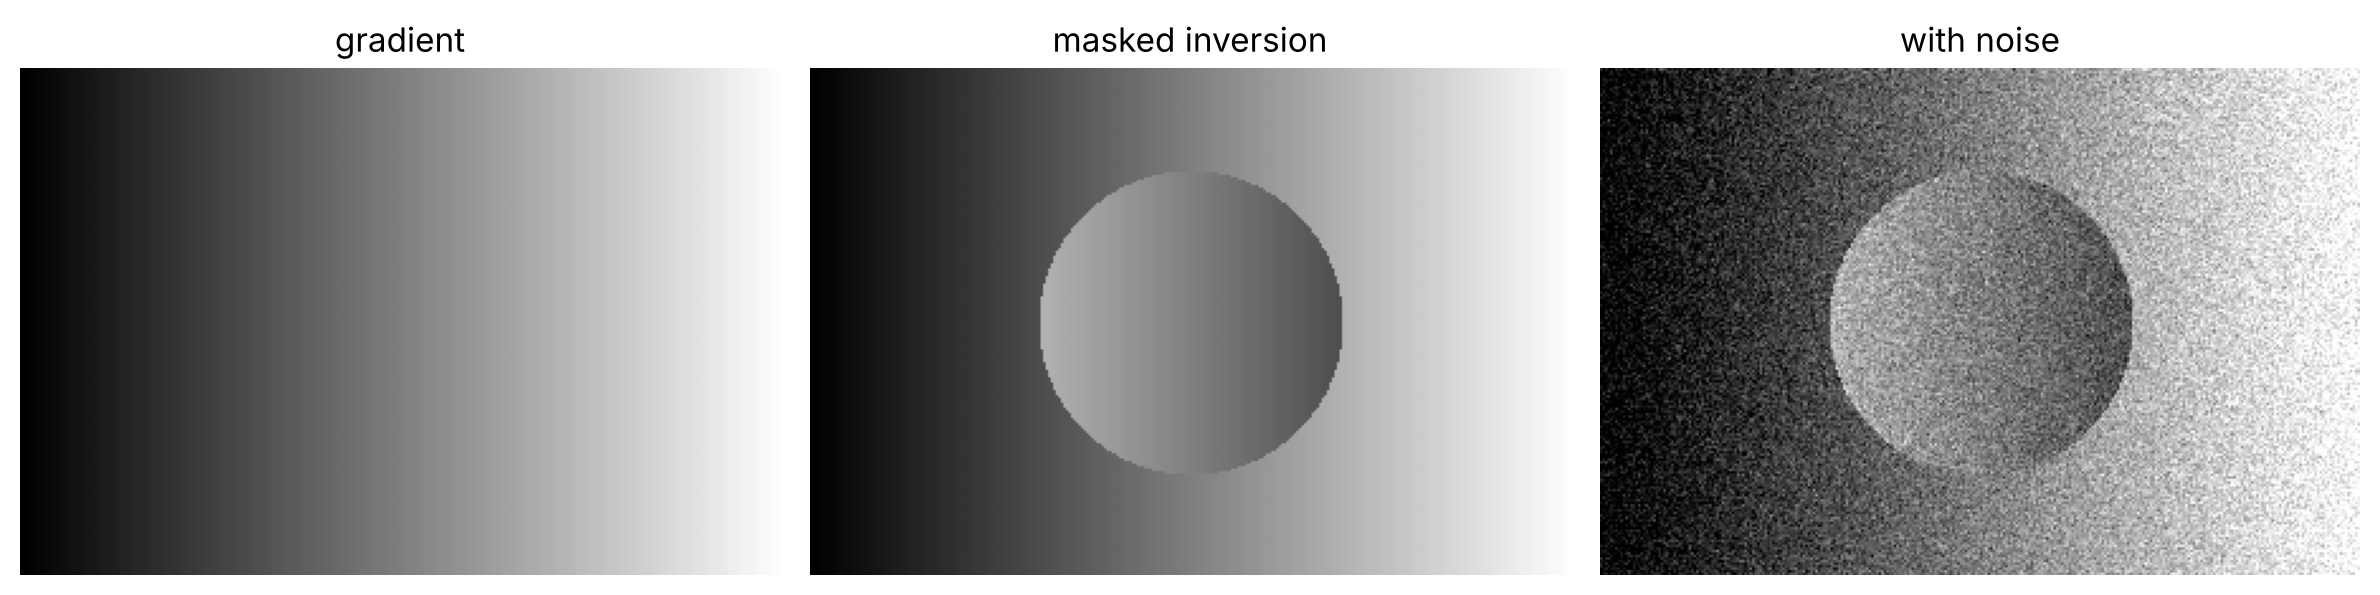

image shape: (200, 300) dtype: uint8


In [15]:
import matplotlib.pyplot as plt

h, w = 200, 300
yy, xx = np.mgrid[0:h, 0:w]                     # pixel coordinates
gradient = (xx / w * 255).astype(np.uint8)       # left-to-right gradient
circle = (xx - 150) ** 2 + (yy - 100) ** 2 < 60 ** 2
img = gradient.copy()
img[circle] = 255 - img[circle]                  # invert pixels inside the circle
noisy = np.clip(img + rng.normal(0, 25, img.shape), 0, 255).astype(np.uint8)

fig, axes = plt.subplots(1, 3, figsize=(12, 3))
for ax, im, title in zip(axes, [gradient, img, noisy], ["gradient", "masked inversion", "with noise"]):
    ax.imshow(im, cmap="gray", vmin=0, vmax=255)
    ax.set_title(title)
    ax.axis("off")
plt.tight_layout()
plt.show()
print("image shape:", img.shape, "dtype:", img.dtype)

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

## جمع‌بندی

- آرایهٔ NumPy هم‌نوع و پیوسته در حافظه است و به همین دلیل سریع است.
- به‌جای حلقه، **برداری** فکر کنید: عملیات روی کل آرایه.
- اندیس‌گذاری بولی ابزار اصلی فیلتر کردن داده است.
- پخش اجازه می‌دهد آرایه‌های با شکل متفاوت را بدون حلقه با هم ترکیب کنیم.
- `axis` مشخص می‌کند تجمیع در امتداد کدام بُعد انجام شود.
- برای تکرارپذیری، همیشه مولد تصادفی را با `seed` بسازید.

</div>

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

## تمرین‌ها

هر تمرین را در سلول کد زیر آن حل کنید. پاسخ پیشنهادی در پوشهٔ `solutions` آمده است.

۱. آرایه‌ای از دمای ۳۰ روز (اعداد تصادفی نرمال با میانگین ۲۵ و انحراف معیار ۵) بسازید. تعداد روزهایی که دما بالای میانگین بوده و میانگین دمای آن روزها را حساب کنید.

۲. بدون حلقه، جدول ضرب ۱ تا ۹ را به‌صورت یک ماتریس ۹×۹ بسازید. (راهنما: پخش یک آرایهٔ ستونی و یک آرایهٔ سطری)

۳. ماتریس `scores` بالا را طوری مقیاس کنید که هر ستون بین ۰ و ۱ قرار بگیرد (Min-Max Scaling).

۴. با `rng.integers` پرتاب دو تاس را ۱۰۰٬۰۰۰ بار شبیه‌سازی کنید و احتمال اینکه جمع دو تاس ۷ شود را تخمین بزنید. مقدار دقیق آن ۶/۱ است.

۵. در تصویر بالا، پیکسل‌های نیمهٔ پایین را تیره‌تر کنید (مقدارشان را نصف کنید) و نتیجه را نمایش دهید.

</div>

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

**تمرین ۱.** آرایه‌ای از دمای ۳۰ روز (اعداد تصادفی نرمال با میانگین ۲۵ و انحراف معیار ۵) بسازید. تعداد روزهایی که دما بالای میانگین بوده و میانگین دمای آن روزها را حساب کنید.

</div>

In [ ]:
# پاسخ خود را اینجا بنویسید


<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

**تمرین ۲.** بدون حلقه، جدول ضرب ۱ تا ۹ را به‌صورت یک ماتریس ۹×۹ بسازید. (راهنما: پخش یک آرایهٔ ستونی و یک آرایهٔ سطری)

</div>

In [ ]:
# پاسخ خود را اینجا بنویسید


<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

**تمرین ۳.** ماتریس `scores` بالا را طوری مقیاس کنید که هر ستون بین ۰ و ۱ قرار بگیرد (Min-Max Scaling).

</div>

In [ ]:
# پاسخ خود را اینجا بنویسید


<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

**تمرین ۴.** با `rng.integers` پرتاب دو تاس را ۱۰۰٬۰۰۰ بار شبیه‌سازی کنید و احتمال اینکه جمع دو تاس ۷ شود را تخمین بزنید. مقدار دقیق آن ۶/۱ است.

</div>

In [ ]:
# پاسخ خود را اینجا بنویسید


<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

**تمرین ۵.** در تصویر بالا، پیکسل‌های نیمهٔ پایین را تیره‌تر کنید (مقدارشان را نصف کنید) و نتیجه را نمایش دهید.

</div>

In [ ]:
# پاسخ خود را اینجا بنویسید
